## Conceptual

1 - Explain how k-fold cross-validation is implemented.

Answer: K-fold crossvalidation works by randomly splitting the dataset into k roughly equalysized folds. For each of the k iterations, one fold is held out as the vali set, while the remaining k−1 folds are used to train the model. The model is fit on the training folds, predictions are made on the val fold, and a performance metric is computed. This process is repeated k times so that each fold serves as the val set exactly once. The final cross-validation estimate is the average of the k performance values


2 - What are the advantages and disadvantages of k-fold cross-validation relative to:

i The validation set approach?
Answer:
- Advantages: every observation is used for both train and val, lower variance in the estimate, less dependence on a single random split
- Disadvantages: More computationally expensive (k models vs 1) but still some randomnes from fold assignment

ii LOOCV?

Answer:
- Advantages: lower computational cost (k models vs n); typically similar or only slightly higher variance, often a good bias variance tradeoff
- Disadvantages: higher bias than LOOCV (each training set has (k−1)/k of the data) and choice of k affects the tradeoff


## Practical

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.formula.api import ols
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
Auto = pd.read_csv("../ISLR/data/Auto.csv", na_values="?", index_col=0)
Auto = Auto.dropna()
Auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
1,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
2,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
3,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
4,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
5,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [3]:
print("Number of predictors:", Auto.shape[1])
print("Predictor names:", list(Auto.columns))

Number of predictors: 9
Predictor names: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year', 'origin', 'name']


In [4]:
print("Number of data points:", len(Auto))
print(Auto.describe())

Number of data points: 392
              mpg   cylinders  displacement  horsepower       weight  \
count  392.000000  392.000000    392.000000  392.000000   392.000000   
mean    23.445918    5.471939    194.411990  104.469388  2977.584184   
std      7.805007    1.705783    104.644004   38.491160   849.402560   
min      9.000000    3.000000     68.000000   46.000000  1613.000000   
25%     17.000000    4.000000    105.000000   75.000000  2225.250000   
50%     22.750000    4.000000    151.000000   93.500000  2803.500000   
75%     29.000000    8.000000    275.750000  126.000000  3614.750000   
max     46.600000    8.000000    455.000000  230.000000  5140.000000   

       acceleration        year      origin  
count    392.000000  392.000000  392.000000  
mean      15.541327   75.979592    1.576531  
std        2.758864    3.683737    0.805518  
min        8.000000   70.000000    1.000000  
25%       13.775000   73.000000    1.000000  
50%       15.500000   76.000000    1.000000  
75

In [5]:
corr_matrix = Auto.drop(columns=['name'], errors='ignore').select_dtypes(include=[np.number]).corr()
print(corr_matrix)

                   mpg  cylinders  displacement  horsepower    weight  \
mpg           1.000000  -0.777618     -0.805127   -0.778427 -0.832244   
cylinders    -0.777618   1.000000      0.950823    0.842983  0.897527   
displacement -0.805127   0.950823      1.000000    0.897257  0.932994   
horsepower   -0.778427   0.842983      0.897257    1.000000  0.864538   
weight       -0.832244   0.897527      0.932994    0.864538  1.000000   
acceleration  0.423329  -0.504683     -0.543800   -0.689196 -0.416839   
year          0.580541  -0.345647     -0.369855   -0.416361 -0.309120   
origin        0.565209  -0.568932     -0.614535   -0.455171 -0.585005   

              acceleration      year    origin  
mpg               0.423329  0.580541  0.565209  
cylinders        -0.504683 -0.345647 -0.568932  
displacement     -0.543800 -0.369855 -0.614535  
horsepower       -0.689196 -0.416361 -0.455171  
weight           -0.416839 -0.309120 -0.585005  
acceleration      1.000000  0.290316  0.212746  

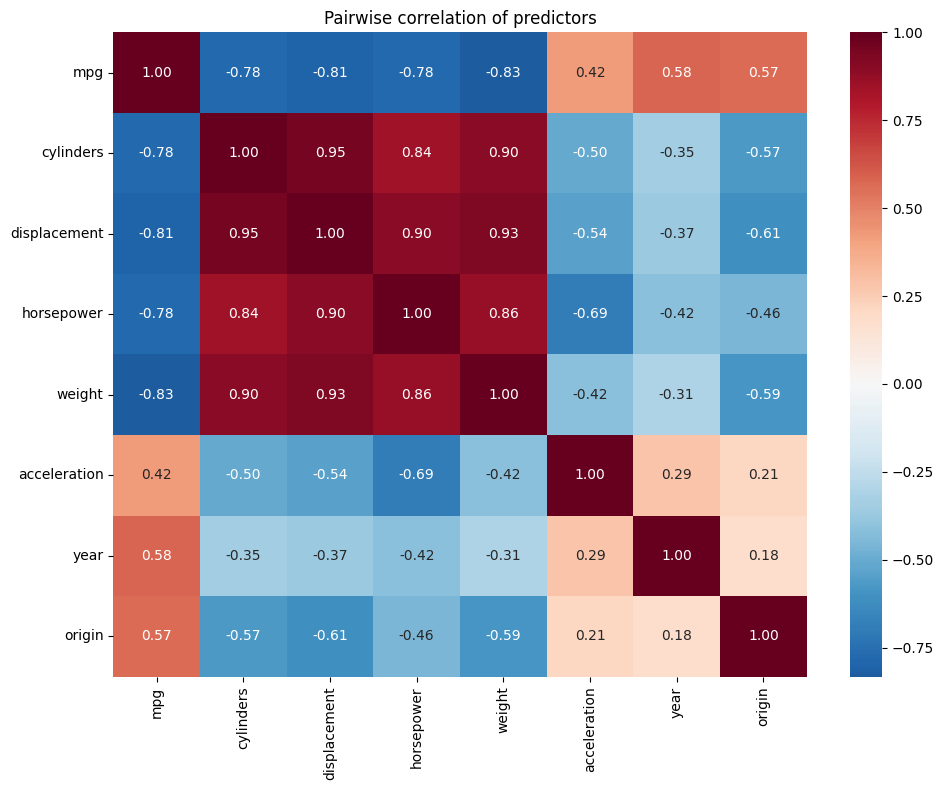

In [6]:
plt.figure(figsize=(10, 8))

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Pairwise correlation of predictors')
plt.tight_layout()

plt.show()

In [7]:
def boot_fn_linear(data, index):
    subset = data.iloc[index]
    model = ols('mpg ~ horsepower', data=subset).fit()
    return model.params.values

n = len(Auto)
params_full = boot_fn_linear(Auto, np.arange(n))
print("Coefficients on full data (b0, b1):", params_full)

np.random.seed(42)
print("Bootstrap sample 1:", boot_fn_linear(Auto, np.random.choice(n, n, replace=True)))
print("Bootstrap sample 2:", boot_fn_linear(Auto, np.random.choice(n, n, replace=True)))

Coefficients on full data (b0, b1): [39.93586102 -0.15784473]
Bootstrap sample 1: [40.46687881 -0.1637381 ]
Bootstrap sample 2: [40.4688335  -0.16255182]


In [8]:
boot_coefs = np.array([boot_fn_linear(Auto, np.random.choice(n, n, replace=True)) for _ in range(1000)])
boot_se = np.std(boot_coefs, axis=0)

print("Bootstrap Statistics (1000 replications):")
print("               original    bias       std. error")
print(f"(Intercept)    {params_full[0]:.4f}     {np.mean(boot_coefs[:,0]) - params_full[0]:.6f}   {boot_se[0]:.4f}")
print(f"horsepower     {params_full[1]:.4f}     {np.mean(boot_coefs[:,1]) - params_full[1]:.6f}   {boot_se[1]:.4f}")

Bootstrap Statistics (1000 replications):
               original    bias       std. error
(Intercept)    39.9359     0.033518   0.8687
horsepower     -0.1578     -0.000499   0.0075


In [9]:
model_linear = ols('mpg ~ horsepower', data=Auto).fit()

print(model_linear.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     39.9359      0.717     55.660      0.000      38.525      41.347
horsepower    -0.1578      0.006    -24.489      0.000      -0.171      -0.145


Interpretation: 


Bootstrap SE(b0)~0.87 and SE(b1)=0.0075, while formula-based SE(b0)~0.72 and SE(b1) = 0.006. The two methods give similar estimates and agree on the order of magnitude of the uncertainty. The slightly larger bootstrap SEs may reflect model misspecification

In [10]:
def boot_fn_quad(data, index):
    subset = data.iloc[index].copy()
    subset['horsepower2'] = subset['horsepower'] ** 2
    model = ols('mpg ~ horsepower + horsepower2', data=subset).fit()
    return model.params.values

params_quad_full = boot_fn_quad(Auto, np.arange(n))
np.random.seed(1)
boot_quad = np.array([boot_fn_quad(Auto, np.random.choice(n, n, replace=True)) for _ in range(1000)])
boot_quad_se = np.std(boot_quad, axis=0)

print("Bootstrap Statistics (1000 replications):")
print("               original    bias         std. error")
print(f"(Intercept)    {params_quad_full[0]:.4f}     {np.mean(boot_quad[:,0]) - params_quad_full[0]:.6f}   {boot_quad_se[0]:.4f}")
print(f"horsepower     {params_quad_full[1]:.4f}     {np.mean(boot_quad[:,1]) - params_quad_full[1]:.6f}   {boot_quad_se[1]:.4f}")
print(f"horsepower²    {params_quad_full[2]:.6f}  {np.mean(boot_quad[:,2]) - params_quad_full[2]:.8f}  {boot_quad_se[2]:.6f}")

Bootstrap Statistics (1000 replications):
               original    bias         std. error
(Intercept)    56.9001     0.022007   2.1023
horsepower     -0.4662     -0.000720   0.0335
horsepower²    0.001231  0.00000384  0.000121


In [11]:
Auto['horsepower2'] = Auto['horsepower'] ** 2
model_quad = ols('mpg ~ horsepower + horsepower2', data=Auto).fit()

print(model_quad.summary().tables[1])

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      56.9001      1.800     31.604      0.000      53.360      60.440
horsepower     -0.4662      0.031    -14.978      0.000      -0.527      -0.405
horsepower2     0.0012      0.000     10.080      0.000       0.001       0.001


Summary: 

Bootstrap SE(b0) ~2.10, SE(b1) ~ 0.034, SE(b2) ~ 0.00012 vs formula SE(b0) ~ 1.80, SE(b1)~0.031, SE(b2)~ 0.00012. All three coefficients show strong agreement between methods

Interpretation:

The close match between bootstrap and formula SEs indicates the quadratic model fits the data well and satisfies the usual regression assumptions (linearity in parameters, homoscedasticity)

The positive quadratic term (b > 0) captures curvature: 

- mpg declines with horsepower at a diminishing rate (the relationship flattens at high horsepower). Unlike the linear model, there is no sign of misspecification here